# Marnitz van den Heever - DSA2 Final Assignment Submition

Import required libraries to execute program succesfully

In [6]:
#import required libraries
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from ipywidgets import interact
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import display

<br><br>Load maze image and view image mode<br>
Convert maze image into a numpy array and determine shape of array

Format of image loaded: RGBA
Shape of maze(1).png as numpy array: (210, 210, 4)


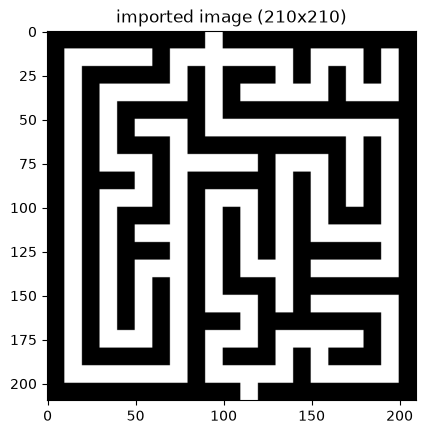

In [12]:
#import maze(1).png
#matplotlib documentation recommends using PIL.image instead of matplotlib.image.imread
#Read an image from a file into a numpy array
img_path = "maze(1).png"

#Confirm format of image
print(f"Format of image loaded: {Image.open(img_path).mode}")

maze_1 = np.array(Image.open(img_path))

#imported image converted to numpy array - display the array
#print(maze_1)

#output number of rows, columns and colour channels
print(f"Shape of maze(1).png as numpy array: {maze_1.shape}")


#[255, 255, 255, 255] indicates a white pixel, i.e. pathway
#[0, 0, 0, 255] indicates a black pixel, i.e. wall
#Since image is black and white, we convert it to a binary matrix

#display the imported image
plt.imshow(maze_1)
plt.title(f"imported image ({maze_1.shape[1]}x{maze_1.shape[0]})")
plt.show()

<br><br>Initial loaded numpy array is size of 210 x 210 <br>
It's required to resize the array to 21 x 21 <br> <br>

Determine step size divide factor to resize the array <br>
Apply step size divide factor to resize array to array

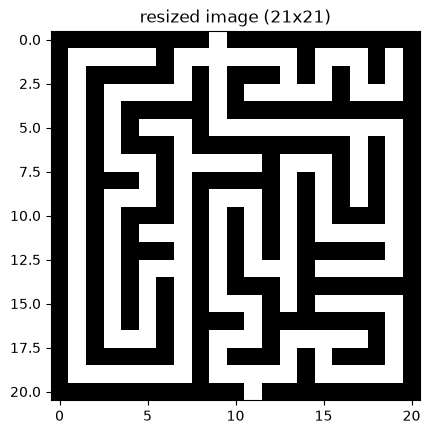

Height of resized image: 21
width of resized image: 21


In [32]:
#step size = ((210-1)-0)/(21-1) = 10.45

#determine the current height (rows) and width (columns) of the imported image
height = maze_1.shape[0]
width = maze_1.shape[1]

#array start at index 0 hence the -1 for the starting index
#force type as integer - Rounds down to the nearest integer
row_i = np.linspace(0, height - 1, 21).astype(int)
col_i = np.linspace(0, width - 1, 21).astype(int)

#resize the image to our 21x21 condition
maze_1_21_21 = maze_1[np.ix_(row_i, col_i)]

#Calculate height and width of resized matrix
height_21_21 = maze_1_21_21.shape[0]
width_21_21 = maze_1_21_21.shape[1]

#display resized image
plt.imshow(maze_1_21_21)
plt.title(f"resized image ({maze_1_21_21.shape[1]}x{maze_1_21_21.shape[0]})")
plt.show()
print(f"Height of resized image: {height_21_21}")
print(f"width of resized image: {width_21_21}")

<br><br>Convert resized image to binary matrix where: <br>
1 = wall<br>
0 = path<br><br>
Given the RGBA PNG colour array, we can test if any Red/Blue/Green colour is omitted:<br>
If any colour is present set to 1 (wall)<br> 
Iif no colour is omitted set 0 (pathway)<br>

In [19]:
maze_grid = np.where(maze_1_21_21[:, :, 0] == 0, 1, 0)
print(maze_grid)
print(f"Shape of binary matrix: {maze_grid.shape}")

[[1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1]
 [1 0 0 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 1]
 [1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 0 1 0 1]
 [1 0 1 0 0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 1]
 [1 0 1 0 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1]
 [1 0 1 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 1]
 [1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 0 1]
 [1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 1 0 1 0 1]
 [1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 0 1 0 1 0 1]
 [1 0 1 0 0 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 1]
 [1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 1 1 0 1]
 [1 0 1 0 1 0 0 0 1 0 1 0 1 0 1 0 0 0 0 0 1]
 [1 0 1 0 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 0 1]
 [1 0 1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1]
 [1 0 1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1]
 [1 0 1 0 1 0 1 0 1 0 0 0 1 0 1 0 0 0 0 0 1]
 [1 0 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1]
 [1 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 1]
 [1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 1]
 [1 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 1]
 [1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1]]
Shape of binary matrix: (21, 21)


<br><br>Dynamically find the entrance/exit of the maze - return the element(s) position of entrance/exit <br>
Assignment specifies that the starting point of the maze is at the top row:<br>
Assign top row as entrance<br>
Assign bottom row as exit

In [20]:
#Find the entrance/starting point of the binary maze, return the element(s)
#Ring fence only the first/last row and column
entrances = []

#Find the elements in the binary maze with value of 0, if 0 then append to entrances array
for row, col in np.argwhere(maze_grid == 0):
    if row in (0, maze_grid.shape[0] - 1) or col in (0, maze_grid.shape[1] - 1):
        entrances.append((int(row), int(col)))

print(f"Binary maze entrance points: {entrances}")

#Assignment allocates the entrance to the top row, so exist subsequently must be last row

starting_point=entrances[0]
print(f"Binary maze starting point: {starting_point}")
exit_point=entrances[1]
print(f"Binary maze exit point: {exit_point}")

Binary maze entrance points: [(0, 9), (20, 11)]
Binary maze starting point: (0, 9)
Binary maze exit point: (20, 11)


<br><br>Create modular functions that will be used in backtracking and Las Vegas approach<br>
Assignment specificies allowed movements (no diagonal movements allowed) - include these conditions as part of initial setup

In [25]:
#Possible movement (up/down/left/right) at any given point
movements = [(-1, 0), (1, 0), (0, -1), (0, 1)]

#Determine movements at a point provided
def check_movements(matrix,point):
    n_values =[]
    row,col=point
    
    for r_move, c_move in movements:
        row_get = row + r_move
        col_get = col + c_move
    
        if 0<=row_get<=(height_21_21-1) and 0<=col_get<=width_21_21-1:
            value = int(matrix[row_get, col_get])
            n_values.append(((row_get,col_get),value))            
    return n_values

#Determine if any adjcent elements contain a wall and what moves are valid
def valid_movements_check(movements):
    valid_movements = [points[0] for points in movements if points[1] == 0]
    return valid_movements

#Generate a function to keep track of unique movements to enable backtracking conditions
#Set starting point as the first movement in movement_log
movement_log = [starting_point]
def movement_tracker(movement_log, point):
    if point not in movement_log:
        movement_log.append(point)
    return movement_log

#Identify what unexplored moves are available for backtracking conditions
def unexplored_movements(valid_moves, movement_log):
    unexplored = [point for point in valid_moves if point not in movement_log]
    return unexplored
    
#Choose first available movement if possible and not explored
#Set start point as the first point in the path explored
current_path = [starting_point]
def next_movement(unexplored, current_path):    
    if unexplored:
        next_point = unexplored[0]
        current_path.append(next_point)
        return next_point

    #If no unexplored movements exist, backtrack
    else:
        print("No next movements available - backtrack one step")

        #Go one step back and remove the current position from the path
        current_path.pop()

        #Return to the previous position
        if current_path:
            return current_path[-1]

        #No movements remaining to explore
        return None

#For Las Vegas approach - generate a random next movement with wall constraints
def random_movement(valid_moves):

    #Check if any movements are available
    if not valid_moves:
        return None

    #Randomly select a valid movement
    random_index = np.random.randint(0, len(valid_moves))
    next_move = valid_moves[random_index]

    return next_move

<br><br>**Backtracking function**<br>
Use modular functions as defined above

In [26]:
#Combine into one function for backtracking
def backtracking(matrix,starting_point,exit_point):

    #Set initial conditions
    movement_log = [starting_point]
    movement_all_log = [starting_point]
    current_path = [starting_point]
    current_point = starting_point
    moves=0
    success_count = 0
    
    while current_point != exit_point:
    
        #Step1 Find possible movements
        possible_moves = check_movements(matrix, current_point)
    
        #Step2 Find valid movements
        valid_moves = valid_movements_check(possible_moves)
    
        #Step3 Remove explored movements
        unexplored = unexplored_movements(valid_moves, movement_log)
    
        #Step4 Select next movement
        previous_path_length = len(current_path)
        next_point = next_movement(unexplored, current_path)
        if len(current_path) < previous_path_length:
            print(f"Backtracking to {next_point}")
            current_point = next_point
        
        #Stop if no movements remain
        if next_point is None:
            break
            
        #Step5 Log movement
        movement_all_log.append(next_point)
        movement_tracker(movement_log, next_point)
    
        if current_point != next_point:
            print(f"current point: {current_point} and move to next point {next_point}")
        #Update current point
        current_point = next_point
        moves=moves+1

        if current_point == exit_point:
            success_count += 1
            
    return {
    "moves": moves,
    "movement_log": movement_log,
    "movement_all_log": movement_all_log,
    "current_path": current_path,
    "path_length": len(current_path),
    "success_count": success_count,
    }
    

<br><br>**Las Vegas function**<br>
Use modular functions as defined above

In [27]:
def las_vegas(matrix, starting_point, exit_point):

    #Set initial conditions
    movement_log = [starting_point]
    movement_all_log = [starting_point]
    current_point = starting_point
    moves = 0
    success_count = 0

    #Max 200 moves allowed or until exist is found
    while current_point != exit_point and moves < 200:

        #Step1 Find possible movements
        possible_moves = check_movements(matrix, current_point)

        #Step2 Find valid movements
        valid_moves = valid_movements_check(possible_moves)

        #Step3 Randomly select next movement with wall conditions applied
        next_point = random_movement(valid_moves)

        #Stop if no valid movements exist
        if next_point is None:
            break

        #Step4 Log movement
        movement_all_log.append(next_point)
        movement_tracker(movement_log, next_point)

        #Step5 Update current position
        current_point = next_point
        moves += 1

    #Keep track successful exists
    if current_point == exit_point:
        success_count += 1

    return {
        "success_count": success_count,
        "moves": moves,
        "movement_log": movement_log,
        "movement_all_log": movement_all_log
    }

<br><br>**Generate movement GIF function**

In [29]:
#Function to generate an animation to show the movements of the algorithm
def generate_maze_gif(matrix, movement_all_log, algorithm, starting_point, exit_point, fps=4):

    history = np.array(movement_all_log)

    #create/Overwrite file
    gif_filename = f"maze_{algorithm.lower().replace(' ', '_')}.gif"

    #Generate maze
    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(matrix, cmap="gray_r")

    #Create movement points
    trail, = ax.plot([], [], "b.-", linewidth=2,markersize=4, label="Movement history")

    current_dot, = ax.plot([], [], "ro", markersize=8,label="Current position")

    #Indicate entrance and exit
    ax.plot(starting_point[1], starting_point[0],"go", markersize=9, label="Entrance")

    ax.plot(exit_point[1], exit_point[0],"mo", markersize=9, label="Exit")

    ax.set_xticks([])
    ax.set_yticks([])
    ax.legend()

    #Plot movement point for each frame
    def update(frame):
        path_so_far = history[:frame + 1]

        #Columns
        x = path_so_far[:, 1]
        #Rows
        y = path_so_far[:, 0] 

        trail.set_data(x, y)
        current_dot.set_data([x[-1]], [y[-1]])

        ax.set_title(f"{algorithm} - Movement {frame}")

        return trail, current_dot

    #Generate gif for each frame
    gif = FuncAnimation(
        fig,
        update,
        frames=len(history),
        interval=1000 / fps,
        blit=False,
        repeat=False
    )

    
    gif.save(gif_filename, writer=PillowWriter(fps=fps))
    plt.close(fig)

    return gif_filename


### **User input**
**Please select which approach to apply in an attempt to exit the maze:**<br>
*If you want to change the approach, please select a different option from the drop down list and run the processing step*

In [30]:
#ask user what approach they want to take
#Use drop down list to avoid the user selecting an option that is not in scope - we will ipywidgets libraries to force this
def method(user_method=["Backtracking", "Las Vegas"]):
    global method
    method = user_method
    print(f"Active Method: {method}")

interact(method);

interactive(children=(Dropdown(description='user_method', options=('Backtracking', 'Las Vegas'), value='Backtr…

### **Algorithm processing step**
**Please run this step after selecting the method**<br>

current point: (0, 9) and move to next point (1, 9)
current point: (1, 9) and move to next point (2, 9)
current point: (2, 9) and move to next point (3, 9)
current point: (3, 9) and move to next point (4, 9)
current point: (4, 9) and move to next point (5, 9)
current point: (5, 9) and move to next point (5, 10)
current point: (5, 10) and move to next point (5, 11)
current point: (5, 11) and move to next point (5, 12)
current point: (5, 12) and move to next point (5, 13)
current point: (5, 13) and move to next point (5, 14)
current point: (5, 14) and move to next point (5, 15)
current point: (5, 15) and move to next point (5, 16)
current point: (5, 16) and move to next point (5, 17)
current point: (5, 17) and move to next point (6, 17)
current point: (6, 17) and move to next point (7, 17)
current point: (7, 17) and move to next point (8, 17)
current point: (8, 17) and move to next point (9, 17)
No next movements available - backtrack one step
Backtracking to (8, 17)
No next movements av

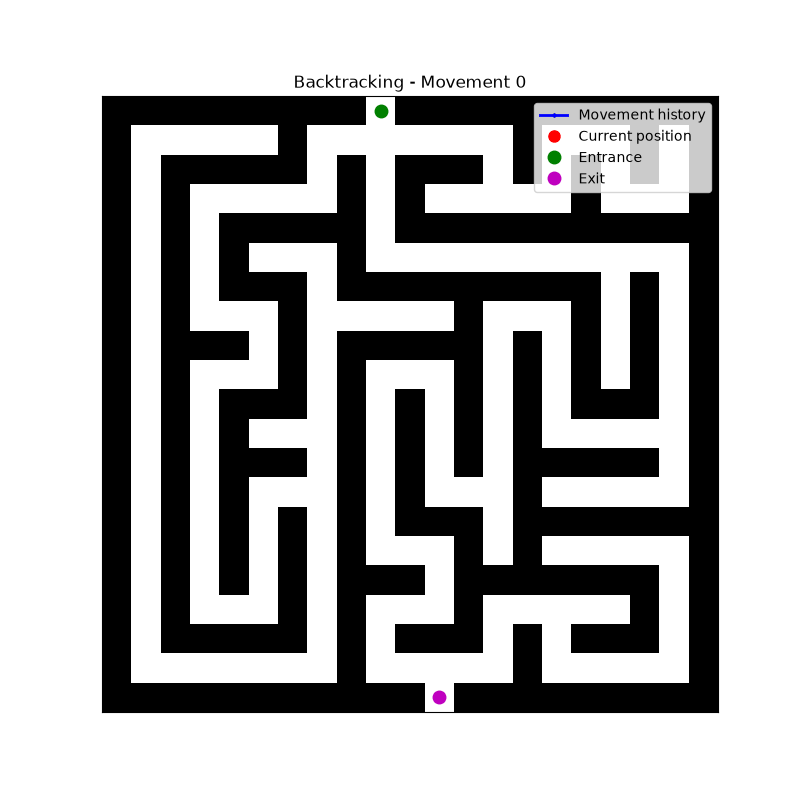

In [39]:
#confirm that the method/approach is captured correctly when a new selection is made
total_runs = 1

if method == "Backtracking":
    result = backtracking(maze_grid, starting_point, exit_point)

elif method == "Las Vegas":
    result = las_vegas(maze_grid, starting_point, exit_point)

print("Successful attempts:", result["success_count"])
print("Total movements:", result["moves"])
print("Unique positions:", len(result["movement_log"]))
print("Total runs:", total_runs)

from IPython.display import Image as NotebookImage, display
gif_file = generate_maze_gif(
    maze_grid,
    result["movement_all_log"],
    method,
    starting_point,
    exit_point
)


display(NotebookImage(filename=gif_file,embed=True))

**To view the visited square for each algorithm please open gif links below:**<br>
*Backtracking:* https://github.com/mjvdheever/DSA2_Coursework/blob/main/maze_backtracking.gif <br>
*Las Vegas:* <br>